# Optimum Progress and Calibration

For weeks 1 and 2, this notebook compares the previous best-so-far, the expected best-so-far saved in `predictions.json`, and the observed best-so-far. It also checks how well the expected outputs match the observed outputs.

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchinfo
from torch import nn, optim
from torch.utils import data

from bayesian_bbo import CONFIG, FUNCTION_SPECS, load_observations

_ = torch.manual_seed(42)


WEEKS = (1, 2, 3, 4)
FUNCTION_IDS = tuple(FUNCTION_SPECS)

data_candidates = [Path("../../data"), Path("data"), Path("../data")]
matches = [path.resolve() for path in data_candidates if (path / "function_1").is_dir()]
if not matches:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")
data_root: Path = matches[0]
print(f"Data root: {data_root}")

Data root: /home/pabloncho/repositories/bayesian-bbo/data


In [3]:
function_id = 3
observations = load_observations(data_root, function_id, up_to_week=WEEKS[-1])

# observations

In [4]:
# Convert observations to tensors and create a reproducible 80/20 split.
X_all = torch.from_numpy(observations.inputs.astype('float32'))
y_all = torch.from_numpy(observations.outputs.reshape(-1, 1).astype('float32'))

split_generator = torch.Generator().manual_seed(42)
indices = torch.randperm(len(X_all), generator=split_generator)
n_validation = max(1, round(0.20 * len(X_all)))
validation_indices = indices[:n_validation]
training_indices = indices[n_validation:]

X_train_tensor = X_all[training_indices]
X_validation_tensor = X_all[validation_indices]
y_train_raw = y_all[training_indices]
y_validation_raw = y_all[validation_indices]

# Fit target scaling on training rows only to avoid validation leakage.
y_mean = y_train_raw.mean()
y_std = y_train_raw.std(unbiased=False)
if y_std.item() == 0:
    raise ValueError('Training targets must have nonzero variance to standardize.')
y_train_tensor = (y_train_raw - y_mean) / y_std
y_validation_tensor = (y_validation_raw - y_mean) / y_std

train_dataset = data.TensorDataset(X_train_tensor, y_train_tensor)
print(f'Train rows: {len(training_indices)}, validation rows: {n_validation}')

Train rows: 15, validation rows: 4


In [5]:
hidden_layer_sizes = (1024, 1024, 512, 256, 128)

hidden_layer_sizes = (16,8) 
if not hidden_layer_sizes or any(
    isinstance(width, bool) or not isinstance(width, (int, np.integer)) or width < 1
    for width in hidden_layer_sizes
):
    raise ValueError('hidden_layer_sizes must contain positive integer layer widths.')

layers = []
input_size = X_train_tensor.shape[1]
for width in hidden_layer_sizes:
    layers.extend([nn.Linear(input_size, int(width)), nn.ReLU()])
    input_size = int(width)
layers.append(nn.Linear(input_size, y_train_tensor.shape[1]))
model = nn.Sequential(*layers)

dummy_input = torch.randn(1, X_train_tensor.shape[1])
dummy_output = model(dummy_input)
assert dummy_output.shape == (1, y_train_tensor.shape[1])
print('Hidden layers:', hidden_layer_sizes)
print('Trainable parameters:', sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)
torchinfo.summary(model, input_size=(1, X_train_tensor.shape[1]))

Hidden layers: (16, 8)
Trainable parameters: 209
Input shape: torch.Size([1, 3])
Output shape: torch.Size([1, 1])


Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 1]                    --
├─Linear: 1-1                            [1, 16]                   64
├─ReLU: 1-2                              [1, 16]                   --
├─Linear: 1-3                            [1, 8]                    136
├─ReLU: 1-4                              [1, 8]                    --
├─Linear: 1-5                            [1, 1]                    9
Total params: 209
Trainable params: 209
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

In [6]:
criterion = nn.MSELoss()
device = torch.device('cpu')
model = model.to(device)

def mean_absolute_error(output, target):
    return torch.mean(torch.abs(output - target)).item()

def unscale_targets(values):
    return values * y_std + y_mean

In [7]:
epochs = int(1e5)
patience = 1e3
min_delta = 1e-4
learning_rate = 1e-3
batch_fraction = 1
train_batch_size = max(1, round(batch_fraction * len(train_dataset)))
train_loader = data.DataLoader(train_dataset, batch_size=train_batch_size, shuffle=True)
optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-3)

train_maes = []
validation_maes = []
train_losses = []
best_validation_mae = float('inf')
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    total = 0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        predictions = model(inputs)
        loss = criterion(predictions, targets)
        loss.backward()
        optimizer.step()
        count = len(inputs)
        running_loss += loss.item() * count
        total += count

    model.eval()
    with torch.no_grad():
        train_predictions = unscale_targets(model(X_train_tensor.to(device)))
        validation_predictions = unscale_targets(model(X_validation_tensor.to(device)))
        train_mae = mean_absolute_error(train_predictions, y_train_raw.to(device))
        validation_mae = mean_absolute_error(validation_predictions, y_validation_raw.to(device))

    train_losses.append(running_loss / total)
    train_maes.append(train_mae)
    validation_maes.append(validation_mae)

    if validation_mae < best_validation_mae - min_delta:
        best_validation_mae = validation_mae
        best_epoch = epoch + 1
        best_model_state = {name: value.detach().clone() for name, value in model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        break

if best_model_state is None:
    raise RuntimeError('Training did not produce a validation checkpoint.')
model.load_state_dict(best_model_state)
print(f'Train rows: {len(train_dataset)}, validation rows: {len(validation_indices)}')
print(f'Batch size: {train_batch_size}, batches per epoch: {len(train_loader)}')
print(f'Best epoch: {best_epoch}, best validation MAE: {best_validation_mae:.4f}')
print(f'Epochs run: {len(train_losses)}')

Train rows: 15, validation rows: 4
Batch size: 15, batches per epoch: 1
Best epoch: 619, best validation MAE: 0.1007
Epochs run: 1619


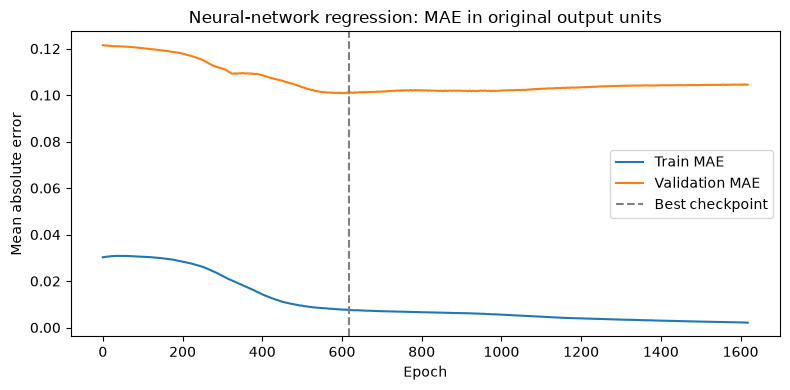

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(train_maes, label='Train MAE')
plt.plot(validation_maes, label='Validation MAE')
plt.axvline(best_epoch - 1, color='gray', linestyle='--', label='Best checkpoint')
plt.title('Neural-network regression: MAE in original output units')
plt.xlabel('Epoch')
plt.ylabel('Mean absolute error')
plt.legend()
plt.tight_layout()
plt.show()

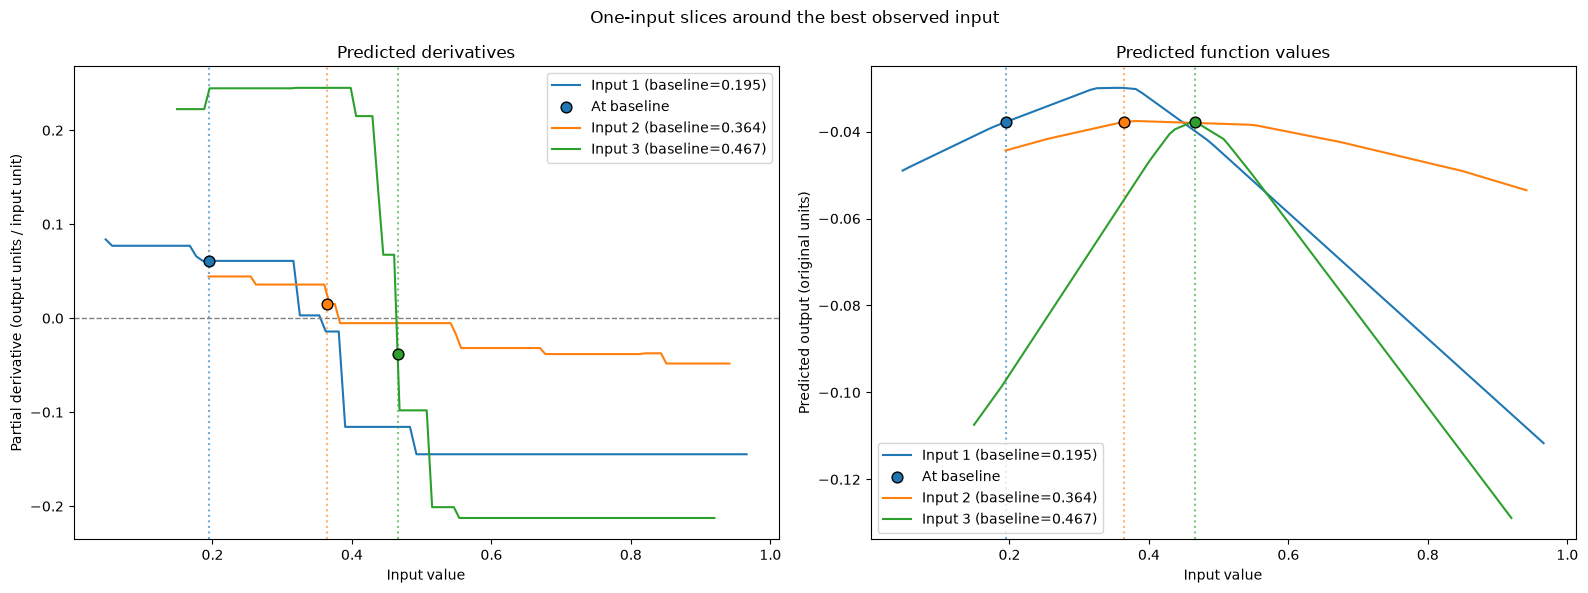

In [9]:
model.eval()
best_observed_index = y_all.squeeze(-1).argmax().item()
baseline = X_all[best_observed_index].to(device)

figure, (derivative_axis, value_axis) = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

with torch.enable_grad():
    baseline_point = baseline.detach().clone().requires_grad_(True)
    baseline_output = unscale_targets(model(baseline_point.unsqueeze(0))).sum()
    baseline_gradients = torch.autograd.grad(baseline_output, baseline_point)[0]

    for input_index in range(len(baseline)):
        values = torch.linspace(
            X_train_tensor[:, input_index].min().item(),
            X_train_tensor[:, input_index].max().item(),
            100,
            device=device,
        )
        points = baseline.repeat(len(values), 1)
        points[:, input_index] = values
        points.requires_grad_(True)
        outputs = unscale_targets(model(points)).squeeze(-1)
        gradients = torch.autograd.grad(outputs.sum(), points)[0]
        derivatives = gradients[:, input_index]
        baseline_value = baseline[input_index].item()
        label = f"Input {input_index + 1} (baseline={baseline_value:.3f})"

        curve, = derivative_axis.plot(
            values.cpu().numpy(),
            derivatives.detach().cpu().numpy(),
            label=label,
        )
        value_axis.plot(
            values.cpu().numpy(),
            outputs.detach().cpu().numpy(),
            color=curve.get_color(),
            label=label,
        )
        for axis, marker_value in zip(
            (derivative_axis, value_axis),
            (baseline_gradients[input_index].item(), baseline_output.item()),
        ):
            axis.axvline(baseline_value, color=curve.get_color(), linestyle=":", alpha=0.6)
            axis.scatter(
                baseline_value,
                marker_value,
                color=curve.get_color(),
                edgecolors="black",
                s=60,
                zorder=3,
                label="At baseline" if input_index == 0 else "_nolegend_",
            )

derivative_axis.axhline(0, color="gray", linestyle="--", linewidth=1)
derivative_axis.set_ylabel("Partial derivative (output units / input unit)")
derivative_axis.set_title("Predicted derivatives")
value_axis.set_ylabel("Predicted output (original units)")
value_axis.set_title("Predicted function values")
for axis in (derivative_axis, value_axis):
    axis.set_xlabel("Input value")
    axis.legend()
figure.suptitle("One-input slices around the best observed input")
figure.tight_layout()
plt.show()

## Global scan and conditional contour planes

Scan the full unit cube with a seeded Sobol pool, then greedily keep high-NN-prediction representatives separated in full-dimensional Euclidean distance. These are candidate neighborhoods, not confirmed distinct basins or global maxima. Distance to the nearest observation is a coverage diagnostic, not uncertainty.

The contours compare the incumbent and these representatives, holding all unplotted inputs at each reference. Stars mark reference coordinates, not measured outcomes. Color scales are shared down each column, but differ between quantities.

The NN retains its existing training split. The comparison Matern 3/2 GP uses all loaded observations through the selected week cutoff; its uncertainty and EI are model-dependent and are not a fair held-out comparison against the NN. No objective is evaluated and no submission or prediction files are written.

In [10]:
from scipy.spatial.distance import cdist
from bayesian_bbo.kernels import make_matern_32_kernel
from bayesian_bbo.optimisation import BayesianOptimizer, OptimisationConfig, find_prediction_regions
from bayesian_bbo.visualisation import plot_prediction_planes

candidate_power = 15
region_count = 3
min_region_distance = 0.5
prediction_batch_size = 4096
scan_seed = CONFIG["random_state"]
gp_alpha = 0.1

def predict_nn_values(points):
    model.eval()
    with torch.no_grad():
        batches = []
        for start in range(0, len(points), prediction_batch_size):
            batch = torch.as_tensor(
                points[start:start + prediction_batch_size], dtype=X_all.dtype, device=device,
            )
            batches.append(unscale_targets(model(batch)).squeeze(-1).cpu().numpy())
    return np.concatenate(batches)

region_points, region_predictions = find_prediction_regions(
    predict_nn_values, observations.dimension, candidate_power=candidate_power,
    region_count=region_count, min_distance=min_region_distance,
    batch_size=prediction_batch_size, seed=scan_seed,
)
reference_points = np.vstack((observations.best_input, region_points))
reference_labels = ["Best observed"] + [f"NN region {index + 1}" for index in range(len(region_points))]

region_gp = BayesianOptimizer(
    observations,
    OptimisationConfig(
        seed=scan_seed, xi=gp_alpha * float(np.std(observations.outputs)),
        kernel=make_matern_32_kernel(observations.dimension, CONFIG["length_caps"][function_id]),
    ),
)
reference_nn = predict_nn_values(reference_points)
reference_gp_mean, reference_gp_std, reference_ei = region_gp.predict(reference_points)
region_summary = pd.DataFrame(reference_points, columns=[
    f"Input {index + 1}" for index in range(observations.dimension)
], index=reference_labels)
region_summary["NN prediction"] = reference_nn
region_summary["GP mean"] = reference_gp_mean
region_summary["GP std"] = reference_gp_std
region_summary["GP EI"] = reference_ei
region_summary["Nearest observation distance"] = cdist(reference_points, observations.inputs).min(axis=1)
region_summary["Observed output"] = [observations.best_output] + [np.nan] * len(region_points)

assert np.allclose(reference_nn[1:], region_predictions)
assert np.all((reference_points >= 0) & (reference_points <= 1))
if len(region_points) > 1:
    separation = cdist(region_points, region_points)
    assert np.all(separation[np.triu_indices(len(region_points), 1)] >= min_region_distance)
print(f"Scanned {2 ** candidate_power:,} Sobol points; retained {len(region_points)} separated NN representatives.")
print(f"GP EI: alpha={gp_alpha:g}, xi={region_gp.config.xi:.6g}; NN and GP predictions are not measured outcomes.")
print("Representatives satisfy a distance rule, not a guarantee of distinct basins or global optimality.")
display(region_summary)

Scanned 32,768 Sobol points; retained 3 separated NN representatives.
GP EI: alpha=0.1, xi=0.00807238; NN and GP predictions are not measured outcomes.
Representatives satisfy a distance rule, not a guarantee of distinct basins or global optimality.


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


,Input 1,Input 2,Input 3,NN prediction,GP mean,GP std,GP EI,Nearest observation distance,Observed output
Best observed,0.194638,0.363906,0.466721,-0.037800,-0.005895,0.000112,0.000000,0.000000,-0.005895
NN region 1,0.707938,0.983228,0.642332,-0.009996,-0.094315,0.092243,0.007034,0.295304,NaN
NN region 2,0.446885,0.556036,0.530534,-0.022851,-0.063092,0.081630,0.009820,0.203496,NaN
NN region 3,0.203130,0.998926,0.584475,-0.032225,-0.069626,0.065728,0.004578,0.184329,NaN


### Compare contour planes

Edit `input_pairs` below using zero-based indices: `(0, 1)` means Inputs 1 and 2. Add more pairs to inspect interactions. Each figure spans the full [0, 1] square, with one row per reference and columns for NN prediction, GP mean, GP standard deviation, and GP expected improvement.

The table reports full-dimensional distance to observations. Observations are not overlaid as measured plane values because their remaining coordinates usually differ. GP standard deviation is the fitted predictive uncertainty, not a guarantee of accuracy; EI uses the displayed alpha and incumbent. Disagreement between NN and GP is a reason for caution, not evidence that either is correct.

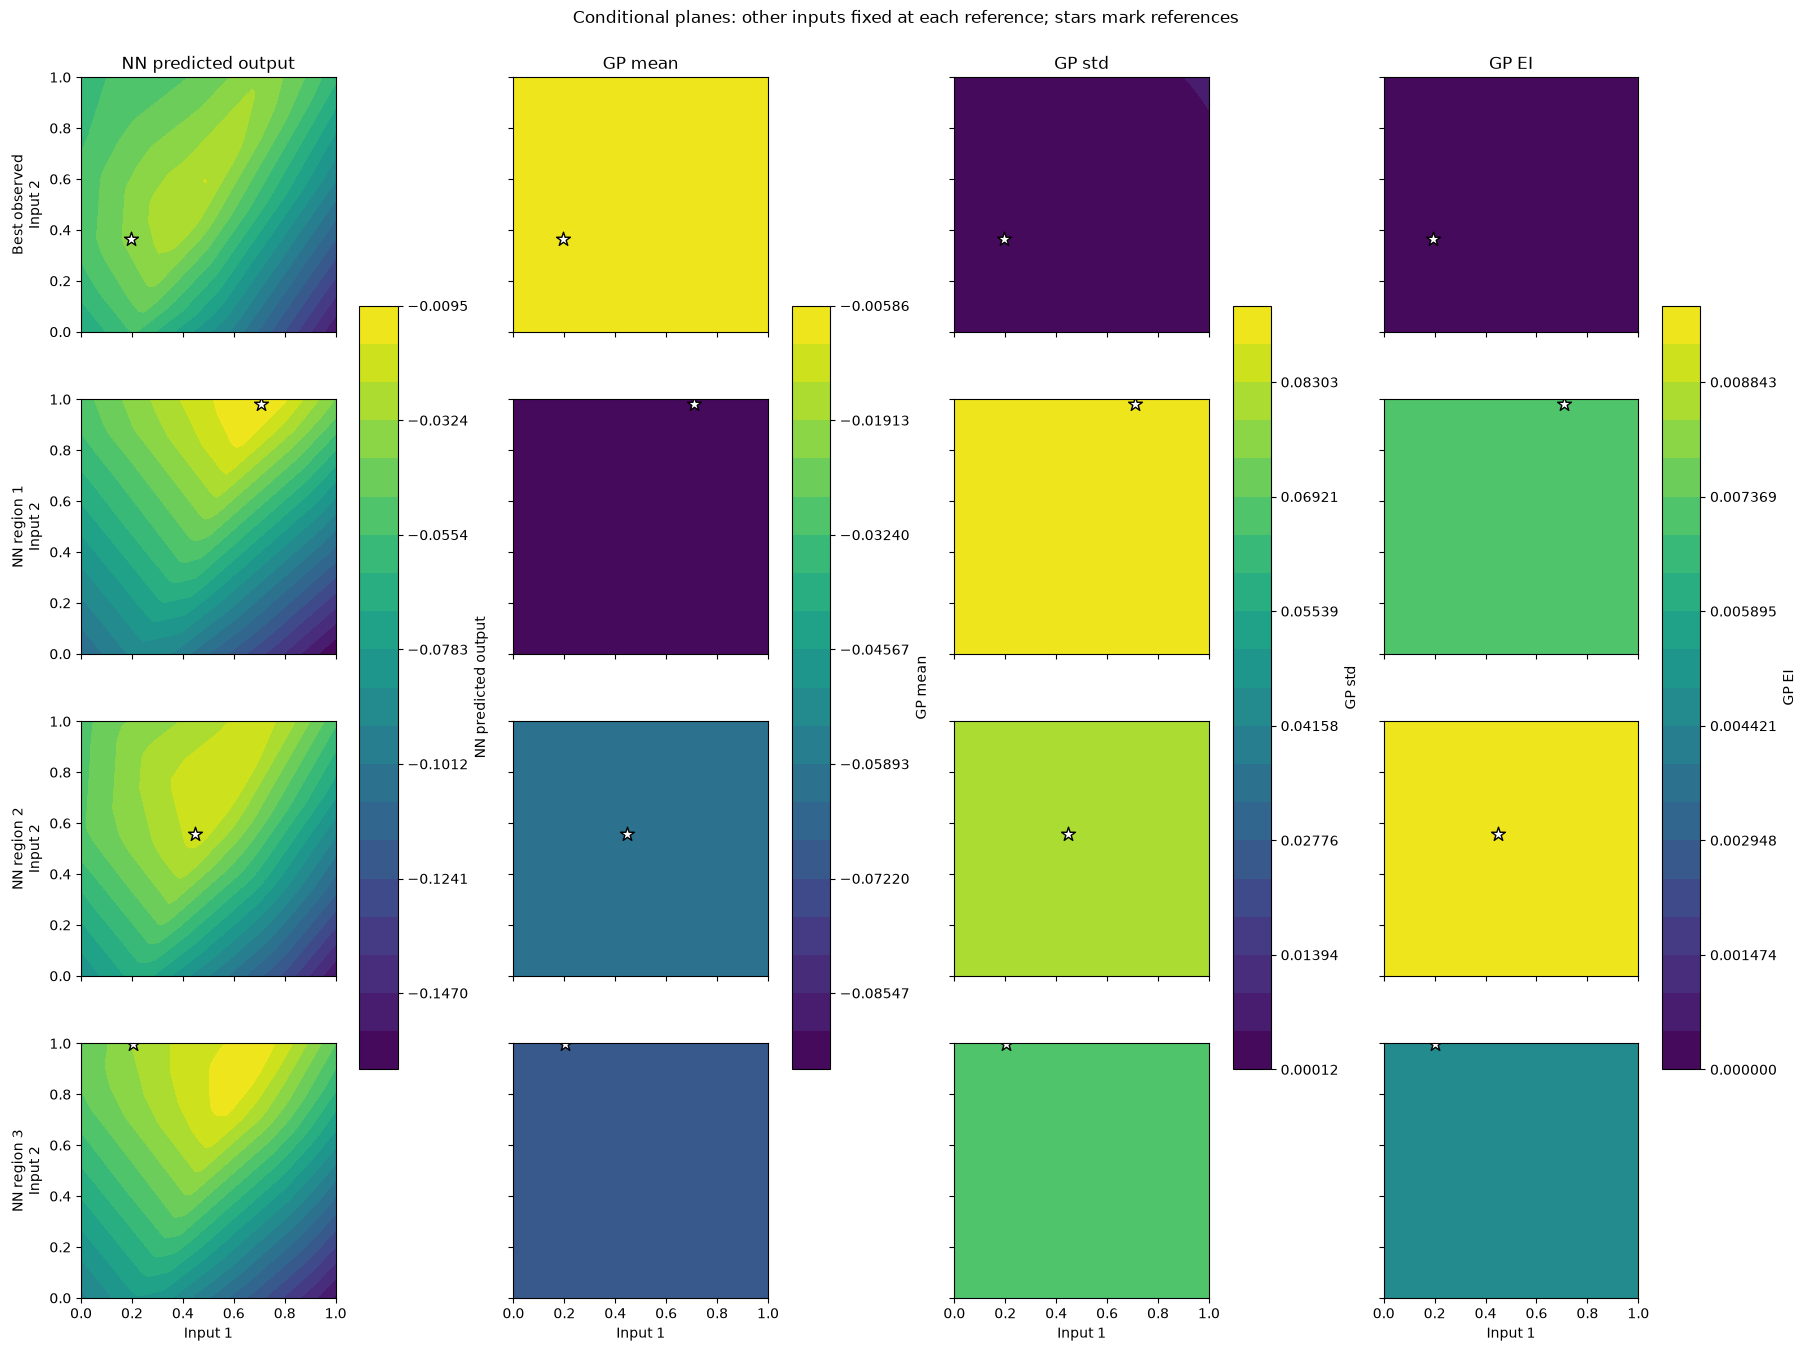

In [11]:
input_pairs = [(0, 1)]
plane_resolution = 50

def predict_comparison_values(points):
    nn_values = predict_nn_values(points)
    gp_batches = []
    for start in range(0, len(points), prediction_batch_size):
        mean, std, ei = region_gp.predict(points[start:start + prediction_batch_size])
        gp_batches.append(np.column_stack((mean, std, ei)))
    return np.column_stack((nn_values, np.concatenate(gp_batches)))

np.testing.assert_allclose(
    predict_comparison_values(reference_points),
    np.column_stack((reference_nn, reference_gp_mean, reference_gp_std, reference_ei)),
)
plane_figures = []
for input_pair in input_pairs:
    plane_figure, plane_axes = plot_prediction_planes(
        predict_comparison_values, reference_points, input_pair=input_pair,
        reference_labels=reference_labels,
        quantity_labels=("NN predicted output", "GP mean", "GP std", "GP EI"),
        grid_size=plane_resolution,
    )
    plane_figures.append(plane_figure)
    plt.show()